# Set Up

In [1]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from pcj.utils import dados, BASE_DIR
from pcj.modelos_ML import selecao_k, k_means, random_forest, knn_regressor
from pcj.visualizacoes import curvas_selecao_k, k_means_clusters

In [2]:
df, metadados, variaveis = dados(r"data\processed\dados_med_tratados.xlsx")

# K-Means
## Escolha de k
Base tratada (`dados_med_tratados.xlsx`: médias mensais, outliers tratados). k de 2 a 10, 30 seeds cada, no espaço da detecção (meses completos, padronizados e reduzidos por PCA). O cotovelo decide (como no projeto, 3.4); a silhueta e o Calinski-Harabasz validam.

In [3]:
# rodadas_k: uma linha por (k, seed); resumo_k: uma linha por k; k_km: o k do cotovelo
rodadas_k, resumo_k, k_km = selecao_k(df, variaveis, verbose=True)
resumo_k

K-Means em 118 meses completos (73 com NaN, não avaliados); 12 componentes principais
k de 2 a 10 x 30 seeds = 270 rodadas
Silhueta (maior média): k = 2
Cotovelo da inércia (kneed): k = 4
Calinski-Harabasz (maior média): k = 2
k escolhido (critério: cotovelo): 4


,k,inercia_media,inercia_dp,silhueta_media,silhueta_dp,calinski_harabasz_media,calinski_harabasz_dp,indicado_silhueta,indicado_cotovelo,indicado_calinski_harabasz
0,2,1382.254520,1.459813,0.203861,0.000553,36.287913,0.160810,True,False,True
1,3,1214.060933,45.986711,0.177622,0.017505,28.558782,3.098376,False,False,False
2,4,1113.929880,12.743735,0.150997,0.031599,23.912080,0.704565,False,True,False
3,5,1043.598763,15.091362,0.132323,0.024363,20.882253,0.702407,False,False,False
4,6,981.105958,17.431081,0.124848,0.017360,19.043722,0.731485,False,False,False
5,7,925.603521,17.543870,0.123762,0.019883,17.781956,0.679295,False,False,False
6,8,875.157000,15.811352,0.126399,0.015158,16.879843,0.583304,False,False,False
7,9,830.891379,15.655073,0.123545,0.014915,16.142094,0.561454,False,False,False
8,10,793.861250,18.681199,0.119388,0.017249,15.444982,0.642718,False,False,False


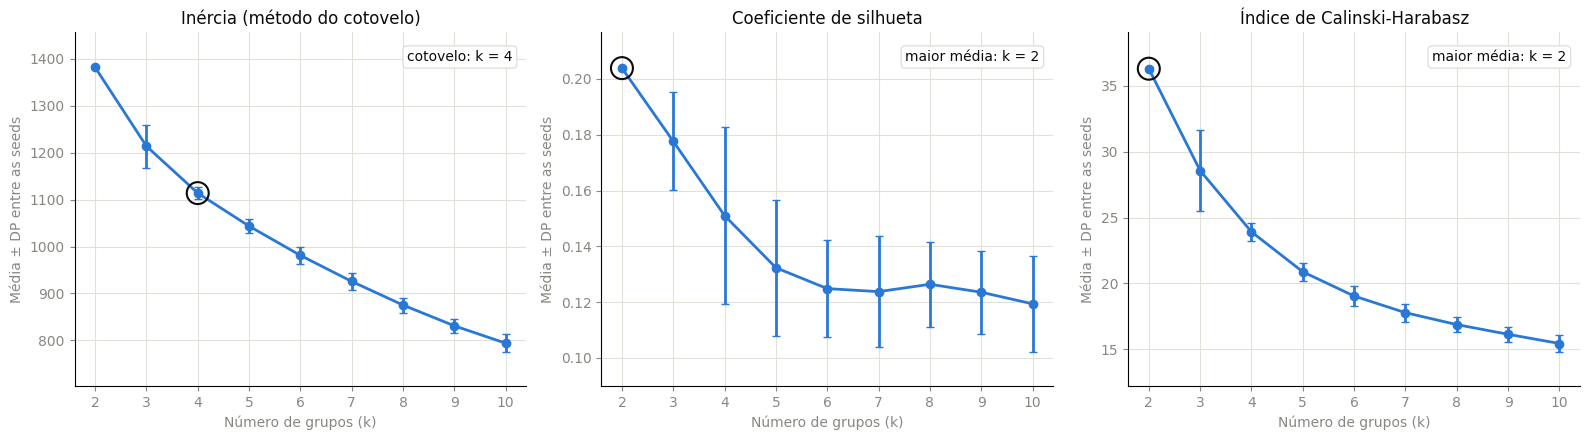

In [4]:
curvas_selecao_k(resumo_k, plot=True, salvar=False)

## Grupos
K-Means com o k escolhido (o melhor de 10 inícios). `tabela_km` tem o grupo de cada mês; `perfil_km` tem a média de cada variável por grupo, na unidade original. As duas figuras mostram os mesmos grupos de dois ângulos: PC1 × PC2 (o plano que guarda mais variação, sem unidade) e TURB. × Cond. (duas das variáveis originais, na unidade delas).

In [5]:
tabela_km, perfil_km = k_means(df, variaveis, n_clusters=k_km, verbose=True)
perfil_km

K-Means com k = 4 em 118 meses completos (73 com NaN, não agrupados); 12 componentes principais
Meses por grupo: [20, 33, 22, 43]


,grupo,meses,COR,TURB.,pH,ALC.,AC.,O.C.,O.D.,Cl,DUR.,Fe,Mn,Cond.,Cianobacteria,C.F.,Clorofila,F
0,0,20,70.150000,26.300000,7.480000,87.500000,10.700000,9.375000,2.940000,59.050000,68.750000,1.100000,0.184000,511.450000,24156.500000,26919.150000,74.679500,0.388000
1,1,33,238.878788,146.575758,7.254545,41.090909,10.696970,9.090909,3.706061,28.454545,43.969697,4.457273,0.215455,187.060606,7266.545455,31527.272727,21.149091,0.197818
2,2,22,65.272727,26.000000,7.218182,63.272727,13.409091,8.154545,3.404545,39.727273,63.909091,1.013182,0.140455,350.727273,11561.181818,4307.272727,26.070909,0.311364
3,3,43,72.511628,30.093023,7.386047,56.395349,8.953488,7.134884,2.439535,38.209302,46.255814,1.553256,0.153256,294.348837,5952.418605,24303.883721,25.403023,0.263488


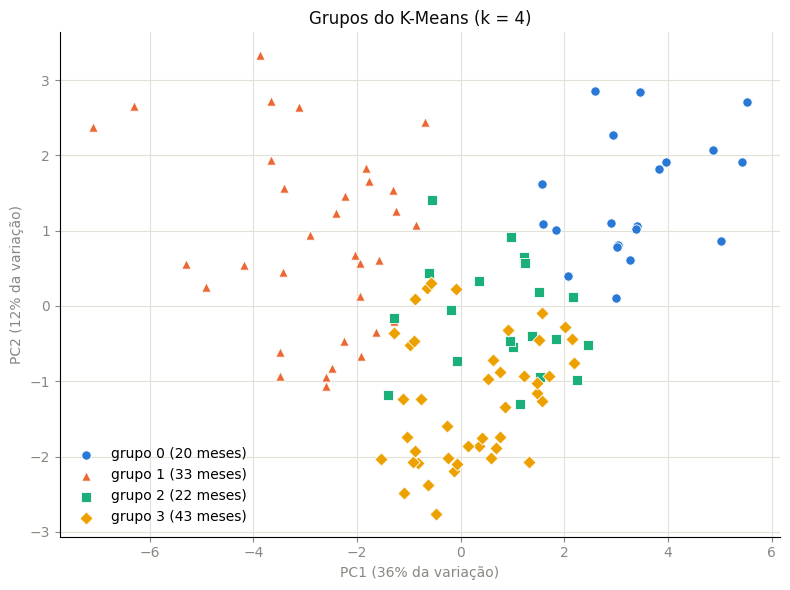

In [6]:
# Grupos no plano dos dois primeiros componentes principais (PC1 × PC2)
k_means_clusters(df, tabela_km, variaveis, plot=True, salvar=False)

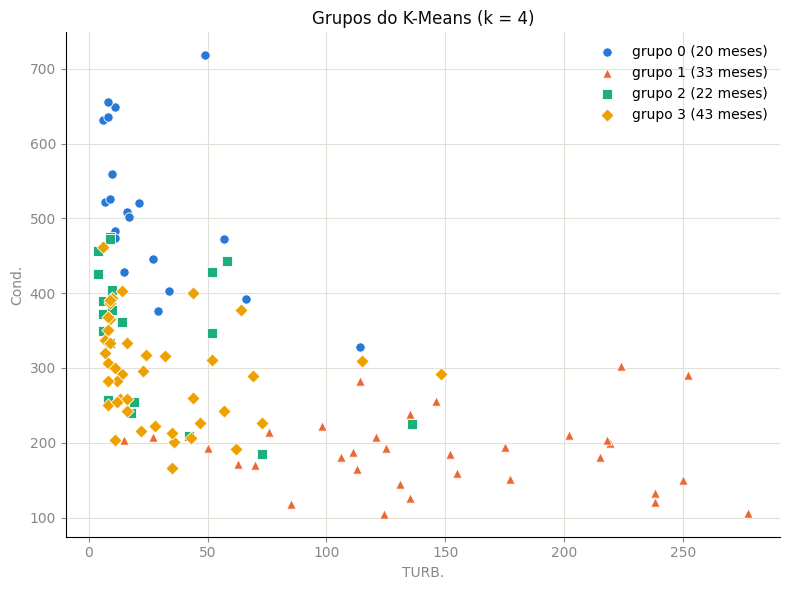

In [7]:
# Os mesmos grupos em duas variáveis originais: turbidez × condutividade
k_means_clusters(df, tabela_km, variaveis, eixos=("TURB.", "Cond."), plot=True, salvar=False)

## Validação da imputação
O projeto (3.1) previa validar a imputação de duas formas: comparando as estatísticas descritivas (feito no notebook `descritiva_evolutiva`) e pelo impacto no K-Means, com o coeficiente de silhueta. Esta seção faz a segunda: a mesma escolha de k e o mesmo K-Means da tratada, agora na base imputada oficial (`dados_med_imputados_knn.xlsx`, KNN padronizado) e, como comparação, na base imputada pela regra do projeto (`dados_med_imputados_pipeline.xlsx`). As duas têm os 191 meses completos; a tratada, 118.

**Ressalva:** o KNN preenche cada célula vazia com a média ponderada dos 13 meses mais parecidos com aquele mês nas outras variáveis. Os meses preenchidos entram perto de meses que já existiam, o que tende a subir a silhueta sem que o agrupamento seja "melhor". A comparação mais firme é a dos 118 meses que estão nas duas bases: eles continuam juntos nos mesmos grupos?

In [8]:
# Bases imputadas (gravadas pelo notebook descritiva_evolutiva): os mesmos meses e colunas da tratada, sem células vazias
imputada_knn, _, _ = dados(r"data\processed\dados_med_imputados_knn.xlsx")
imputada_pipeline, _, _ = dados(r"data\processed\dados_med_imputados_pipeline.xlsx")

# Conferências: os mesmos meses na mesma ordem (a comparação dos grupos usa a posição das linhas) e nenhuma célula vazia
print("Mesmos meses, na mesma ordem:", df["Data"].equals(imputada_knn["Data"]), df["Data"].equals(imputada_pipeline["Data"]))
print("Células vazias:", imputada_knn[variaveis].isna().sum().sum(), imputada_pipeline[variaveis].isna().sum().sum())

Mesmos meses, na mesma ordem: True True
Células vazias: 0 0


### Escolha de k na imputada (KNN)
A mesma `selecao_k` da tratada (k de 2 a 10, 30 seeds cada; o cotovelo decide, como no projeto, 3.4), agora com os 191 meses.

In [9]:
# rodadas_k_knn: uma linha por (k, seed); resumo_k_knn: uma linha por k; k_km_knn: o k do cotovelo
rodadas_k_knn, resumo_k_knn, k_km_knn = selecao_k(imputada_knn, variaveis, verbose=True)
resumo_k_knn

K-Means em 191 meses completos (0 com NaN, não avaliados); 12 componentes principais
k de 2 a 10 x 30 seeds = 270 rodadas
Silhueta (maior média): k = 3
Cotovelo da inércia (kneed): k = 4
Calinski-Harabasz (maior média): k = 2
k escolhido (critério: cotovelo): 4


,k,inercia_media,inercia_dp,silhueta_media,silhueta_dp,calinski_harabasz_media,calinski_harabasz_dp,indicado_silhueta,indicado_cotovelo,indicado_calinski_harabasz
0,2,2256.341811,7.600568,0.214893,0.012268,55.172456,0.823111,False,False,True
1,3,1905.066681,117.706867,0.216218,0.011902,50.318219,8.157275,True,False,False
2,4,1735.612195,8.015865,0.173366,0.039133,42.358201,0.481285,False,True,False
3,5,1627.960378,9.379818,0.147039,0.030929,36.764144,0.478754,False,False,False
4,6,1536.307470,25.424415,0.136149,0.020288,33.221643,1.136443,False,False,False
5,7,1453.511996,32.098181,0.132946,0.014187,30.862960,1.336377,False,False,False
6,8,1367.074441,31.240119,0.136972,0.013283,29.629208,1.283834,False,False,False
7,9,1299.460848,29.928158,0.135864,0.013507,28.309293,1.170352,False,False,False
8,10,1234.143001,31.187900,0.133978,0.013921,27.419466,1.198606,False,False,False


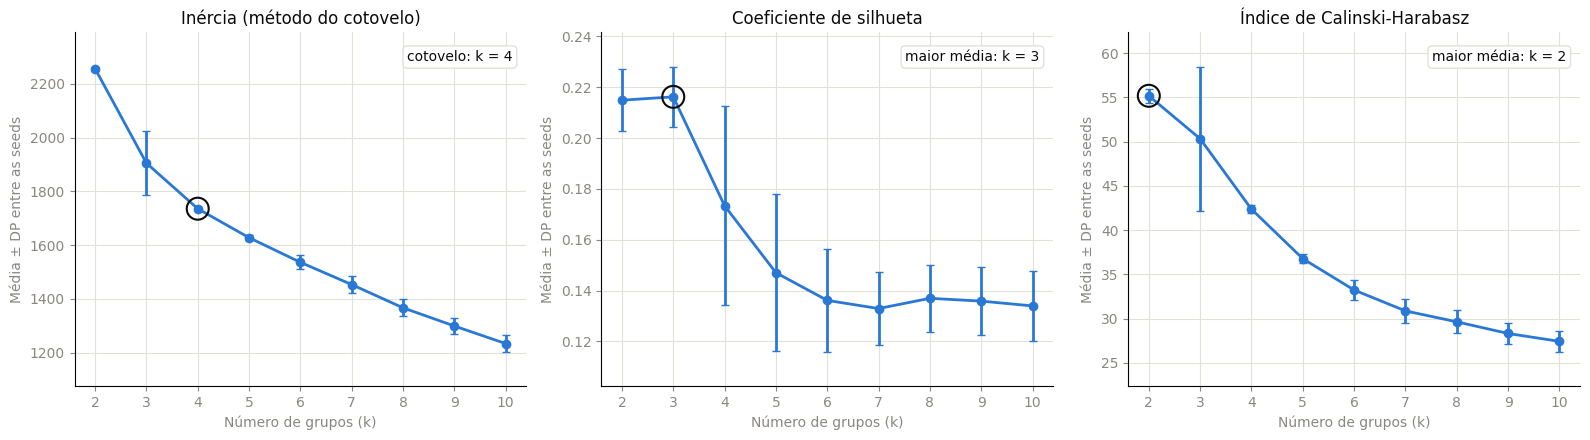

In [10]:
curvas_selecao_k(resumo_k_knn, plot=True, salvar=False)

### Grupos na imputada (KNN)
K-Means com o k do cotovelo da imputada (a regra do projeto em cada base). Se o k mudasse, a tabela cruzada abaixo compararia números de grupos diferentes; o Rand ajustado continua valendo nesse caso.

In [11]:
tabela_km_knn, perfil_km_knn = k_means(imputada_knn, variaveis, n_clusters=k_km_knn, verbose=True)
perfil_km_knn

K-Means com k = 4 em 191 meses completos (0 com NaN, não agrupados); 12 componentes principais
Meses por grupo: [88, 41, 45, 17]


,grupo,meses,COR,TURB.,pH,ALC.,AC.,O.C.,O.D.,Cl,DUR.,Fe,Mn,Cond.,Cianobacteria,C.F.,Clorofila,F
0,0,88,82.568182,35.579545,7.281818,56.413097,11.550598,7.196693,3.031818,38.217052,49.637087,1.541206,0.142600,281.598427,6870.630006,16518.293776,22.946955,0.274558
1,1,41,64.512195,22.804878,7.385366,77.104938,13.598663,9.037826,2.758312,50.804878,59.390244,1.020732,0.197798,440.853659,20257.744576,6351.420417,58.224313,0.348867
2,2,45,244.366840,169.688889,7.240000,41.427099,10.238770,9.035556,3.899251,27.419415,44.536237,4.455983,0.231680,185.111111,7532.545010,30416.818403,21.339476,0.220275
3,3,17,97.058824,25.941176,7.552727,107.517534,9.559697,10.883534,2.459663,73.459815,82.529412,1.234706,0.193067,637.582366,14616.952742,76307.210968,71.310719,0.413078


### Os meses que estão nas duas bases
Os 118 meses completos da tratada também estão na imputada, com os mesmos valores. A tabela cruzada conta, para cada grupo da tratada (linhas), em qual grupo da imputada (colunas) os meses dele caíram. O número do grupo é só um nome: o grupo 0 da tratada não precisa corresponder ao grupo 0 da imputada. O que importa é se os meses que estavam juntos continuam juntos.

O Rand ajustado (`adjusted_rand_score`, do scikit-learn) resume a tabela num número. Ele olha cada par de meses e confere se o par estava junto (ou separado) nas duas bases, descontando a concordância esperada por acaso: 1 = os mesmos grupos; perto de 0 = concordância de acaso; negativo = pior que o acaso.

In [12]:
# Meses que têm grupo na tratada: os 118 completos (os outros 73 ficaram fora do K-Means, com grupo <NA>)
# notna() dá True/False por linha; .loc[comuns, ...] fica só com as linhas True
comuns = tabela_km["grupo"].notna()

rand_knn = adjusted_rand_score(tabela_km.loc[comuns, "grupo"], tabela_km_knn.loc[comuns, "grupo"])
print(f"Rand ajustado, tratada × imputada (KNN), {comuns.sum()} meses: {rand_knn:.3f}")

# crosstab: conta quantos meses há em cada combinação (grupo na tratada, grupo na imputada)
pd.crosstab(tabela_km.loc[comuns, "grupo"], tabela_km_knn.loc[comuns, "grupo"],
            rownames=["tratada"], colnames=["imputada_knn"])

Rand ajustado, tratada × imputada (KNN), 118 meses: 0.485


imputada_knn,0,1,2,3
tratada,,,,
0,0,15,0,5
1,4,0,29,0
2,14,8,0,0
3,37,6,0,0


### Os meses que só entram na imputada
Em qual grupo caem os 73 meses que a tratada deixava fora do K-Means, separados por período: jul–nov/2014 (a estiagem, com valores tratados como outliers), 2016–2019 (41 dos 48 meses tinham alguma variável vazia) e os outros.

In [13]:
# ~ inverte True/False: os meses que não têm grupo na tratada
novos = ~comuns

# .dt.year e .dt.month tiram o ano e o mês da coluna de datas
ano = df.loc[novos, "Data"].dt.year
mes = df.loc[novos, "Data"].dt.month

# Período de cada mês novo: começa como "outros" e é trocado nos dois períodos de interesse
periodo = pd.Series("outros", index=df.index[novos])
periodo[(ano >= 2016) & (ano <= 2019)] = "2016–2019"
periodo[(ano == 2014) & (mes >= 7) & (mes <= 11)] = "jul–nov/2014"

pd.crosstab(periodo, tabela_km_knn.loc[novos, "grupo"], rownames=["periodo"], colnames=["imputada_knn"])

imputada_knn,0,1,2,3
periodo,,,,
2016–2019,22,8,10,1
jul–nov/2014,0,0,0,5
outros,11,4,6,6


### Base de comparação (regra do projeto)
A mesma sequência na `dados_med_imputados_pipeline.xlsx` (média até 5% de faltantes, KNN sem padronizar de 5 a 15% e KNN padronizado de 15 a 30%): escolha de k, grupos, meses comuns e meses novos.

In [14]:
rodadas_k_pipeline, resumo_k_pipeline, k_km_pipeline = selecao_k(imputada_pipeline, variaveis, verbose=True)
resumo_k_pipeline

K-Means em 191 meses completos (0 com NaN, não avaliados); 13 componentes principais
k de 2 a 10 x 30 seeds = 270 rodadas
Silhueta (maior média): k = 2
Cotovelo da inércia (kneed): k = 4
Calinski-Harabasz (maior média): k = 2
k escolhido (critério: cotovelo): 4


,k,inercia_media,inercia_dp,silhueta_media,silhueta_dp,calinski_harabasz_media,calinski_harabasz_dp,indicado_silhueta,indicado_cotovelo,indicado_calinski_harabasz
0,2,2328.076364,87.198821,0.196915,0.013353,49.866161,7.545492,True,False,True
1,3,1985.530377,81.809240,0.194506,0.014145,45.347813,5.278096,False,False,False
2,4,1858.120474,42.130665,0.164180,0.033839,36.303004,2.044658,False,True,False
3,5,1748.812280,21.388140,0.142515,0.034894,31.656432,0.940223,False,False,False
4,6,1656.269137,31.924945,0.132676,0.028699,28.677443,1.235577,False,False,False
5,7,1568.034442,40.881304,0.125693,0.021767,26.848767,1.472441,False,False,False
6,8,1493.367964,35.914891,0.114514,0.015050,25.334810,1.221223,False,False,False
7,9,1411.828791,28.260998,0.115921,0.012772,24.626152,0.942754,False,False,False
8,10,1353.904551,28.435341,0.112617,0.013838,23.563130,0.912093,False,False,False


In [15]:
tabela_km_pipeline, perfil_km_pipeline = k_means(imputada_pipeline, variaveis, n_clusters=k_km_pipeline, verbose=True)
perfil_km_pipeline

K-Means com k = 4 em 191 meses completos (0 com NaN, não agrupados); 13 componentes principais
Meses por grupo: [5, 101, 34, 51]


,grupo,meses,COR,TURB.,pH,ALC.,AC.,O.C.,O.D.,Cl,DUR.,Fe,Mn,Cond.,Cianobacteria,C.F.,Clorofila,F
0,0,5,88.400000,33.200000,7.460000,59.300000,8.900000,7.591913,2.546559,37.900000,59.400000,2.370000,0.214000,425.200000,8526.700000,252170.000000,26.462000,0.268000
1,1,101,72.930693,28.207921,7.298020,60.475248,12.910891,7.438192,2.918796,40.846535,51.161483,1.371768,0.163317,315.056457,7572.955446,12034.030989,26.700594,0.284234
2,2,34,84.294118,27.647059,7.448420,88.926471,10.411765,10.098811,2.747059,61.250000,72.823529,1.185294,0.168824,534.363267,22574.088235,18835.970588,75.770882,0.378529
3,3,51,228.547265,160.549020,7.247059,42.656863,10.196078,9.100000,3.871231,28.607843,44.527920,4.071988,0.215294,189.117647,6687.764706,25943.106697,21.219706,0.228916


In [16]:
rand_pipeline = adjusted_rand_score(tabela_km.loc[comuns, "grupo"], tabela_km_pipeline.loc[comuns, "grupo"])
print(f"Rand ajustado, tratada × imputada (pipeline), {comuns.sum()} meses: {rand_pipeline:.3f}")

pd.crosstab(tabela_km.loc[comuns, "grupo"], tabela_km_pipeline.loc[comuns, "grupo"],
            rownames=["tratada"], colnames=["imputada_pipeline"])

Rand ajustado, tratada × imputada (pipeline), 118 meses: 0.564


imputada_pipeline,0,1,2,3
tratada,,,,
0,1,1,18,0
1,1,2,0,30
2,0,22,0,0
3,2,40,0,1


In [17]:
pd.crosstab(periodo, tabela_km_pipeline.loc[novos, "grupo"], rownames=["periodo"], colnames=["imputada_pipeline"])

imputada_pipeline,0,1,2,3
periodo,,,,
2016–2019,0,26,3,12
jul–nov/2014,1,0,4,0
outros,0,10,9,8


### Resumo
Uma linha por base: os meses agrupados, o k apontado por cada critério, a silhueta no k escolhido (média e desvio padrão das 30 seeds da `selecao_k`) e o Rand ajustado em relação à tratada, nos 118 meses comuns.

In [18]:
# Cada base com o seu resumo da selecao_k, o seu k escolhido e o seu Rand ajustado (a tratada não se compara com ela mesma)
bases = [
    ("tratada", df, resumo_k, k_km, None),
    ("imputada_knn", imputada_knn, resumo_k_knn, k_km_knn, rand_knn),
    ("imputada_pipeline", imputada_pipeline, resumo_k_pipeline, k_km_pipeline, rand_pipeline),
]

linhas = []

for nome_base, base, resumo, k_escolhido, rand in bases:
    # Linha do k escolhido no resumo (as colunas indicado_* são True só na linha do k de cada critério)
    linha_k = resumo[resumo["k"] == k_escolhido].iloc[0]

    linhas.append({
        "base": nome_base,
        "meses_agrupados": len(base[variaveis].dropna()),
        "k_cotovelo": k_escolhido,
        "k_silhueta": int(resumo.loc[resumo["indicado_silhueta"], "k"].iloc[0]),
        "k_calinski_harabasz": int(resumo.loc[resumo["indicado_calinski_harabasz"], "k"].iloc[0]),
        "silhueta_media": linha_k["silhueta_media"],
        "silhueta_dp": linha_k["silhueta_dp"],
        "rand_ajustado": rand,
    })

validacao_km = pd.DataFrame(linhas)
validacao_km

,base,meses_agrupados,k_cotovelo,k_silhueta,k_calinski_harabasz,silhueta_media,silhueta_dp,rand_ajustado
0,tratada,118,4,2,2,0.150997,0.031599,NaN
1,imputada_knn,191,4,3,2,0.173366,0.039133,0.484786
2,imputada_pipeline,191,4,2,2,0.164180,0.033839,0.563942


# Random Forest
Regressão do pH pelas outras variáveis, com validação cruzada em 5 blocos de meses seguidos. A tabela tem as métricas juntando os blocos e o R² de cada bloco; `previsoes_rf` guarda a previsão de cada mês, usada na comparação com a base não tratada (notebook `ML_outliers_nao_tratados`).

In [19]:
# resultado_rf: as métricas (uma linha); previsoes_rf: a previsão de cada mês, feita quando o bloco dele é o de teste
resultado_rf, previsoes_rf = random_forest(df, variaveis, devolver_previsoes=True)
resultado_rf

,variavel,rmse,mae,r2,r2_blocos
0,pH,0.130221,0.104051,0.260104,"[0.162, -0.268, 0.375, -0.103, 0.145]"


# KNN Regressor
Cada variável prevista pelas outras, com validação cruzada em 5 blocos de meses seguidos (GridSearch dentro de cada bloco). O modelo usa as variáveis normalizadas (0 a 1); o RMSE e o MAE estão na unidade de cada variável.

In [20]:
# resultado_knn: uma linha por variável prevista; previsoes_knn: a previsão de cada mês e variável
resultado_knn, previsoes_knn = knn_regressor(df, variaveis, devolver_previsoes=True)
resultado_knn

,variavel,rmse,mae,r2,r2_blocos,melhores_parametros,n_blocos_parametros
0,COR,78.918852,37.885344,0.496810,"[0.387, 0.471, 0.797, 0.638, 0.813]","{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",2
1,TURB.,50.239894,33.599702,0.468770,"[0.614, 0.375, 0.433, 0.342, 0.414]","{'metric': 'manhattan', 'n_neighbors': 15, 'we...",1
2,pH,0.141134,0.111863,0.130892,"[0.201, -0.337, 0.195, -0.306, -0.099]","{'metric': 'euclidean', 'n_neighbors': 13, 'we...",2
3,ALC.,13.295878,9.776063,0.553414,"[0.688, 0.029, 0.498, 0.454, 0.477]","{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",2
4,AC.,5.313244,3.623009,-0.135784,"[-0.438, -0.094, -0.268, -0.47, -0.521]","{'metric': 'euclidean', 'n_neighbors': 13, 'we...",1
5,O.C.,2.496647,1.822802,-0.113796,"[-0.762, -0.597, -0.55, 0.023, -0.466]","{'metric': 'manhattan', 'n_neighbors': 15, 'we...",1
6,O.D.,0.753419,0.598298,0.196735,"[0.297, 0.424, 0.297, 0.1, -1.824]","{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",2
7,Cl,9.698348,7.076877,0.474154,"[-0.229, 0.458, 0.073, 0.659, 0.62]","{'metric': 'euclidean', 'n_neighbors': 9, 'wei...",1
8,DUR.,13.044501,9.727684,0.201696,"[-0.573, -0.31, 0.42, -0.241, -1.019]","{'metric': 'manhattan', 'n_neighbors': 7, 'wei...",2
9,Fe,1.431252,0.865556,0.421603,"[0.32, -0.176, 0.425, 0.443, 0.683]","{'metric': 'manhattan', 'n_neighbors': 11, 'we...",2


# Gravação
Resultados do RF e do KNN, que o notebook `ML_outliers_nao_tratados` lê para a comparação: abas `rf`, `knn`, `previsoes_rf` e `previsoes_knn`. O K-Means não entra (não tem métrica de erro). Como o RF usa random_state=42 e o KNN não tem sorteio, rodar de novo dá os mesmos números.

In [21]:
caminho = BASE_DIR / "data" / "output" / "ML_outliers_tratados.xlsx"

# ExcelWriter permite gravar várias abas no mesmo arquivo
with pd.ExcelWriter(caminho) as arquivo:
    resultado_rf.to_excel(arquivo, sheet_name="rf", index=False)
    resultado_knn.to_excel(arquivo, sheet_name="knn", index=False)
    previsoes_rf.to_excel(arquivo, sheet_name="previsoes_rf", index=False)
    previsoes_knn.to_excel(arquivo, sheet_name="previsoes_knn", index=False)

print("Gravado em:", caminho)

Gravado em: C:\_Master\Programacao\Guilherme-Betta\1_Projects\IC2\IC2\data\output\ML_outliers_tratados.xlsx
